# Figure 5 · Multiple sources and current best reconstructions

**Five selected validation fields.** Columns: NISP Y, JWST, bilinear,
diffusion, ResNet, directResNet (direct-5× variant). Row **b** retains the
face-on disk and its display scale. New rows **a**, **c**, **d** and **e** show
a close projected pair, overlapping elongated sources, a crowded field with
several neighbors, and a close pair with different orientations, respectively.

The new fields were selected from observed NISP/JWST images before inspecting
their model predictions. An observation-only search of validation crops ranked
fields by the second-brightest separated JWST peak; 64 spatially distinct
candidates were visually reviewed. The search script, thresholds, candidate
sheets and selection are retained under `inputs/figure5_multiple_sources_v05/`
and in the selection metadata. Peaks are a browsing aid, not a galaxy catalogue;
projected neighbors need not be physically associated. These examples illustrate
source multiplicity and morphology, not population statistics or a model ranking.

The exporter snapshots best checkpoints in tmux with online W&B. This notebook
only reads saved arrays. Bilinear retains NISP's band and instrumental response.
For future updates retain `inputs/galaxy_examples_selection_v05.json`, set a new
`VERSION` and pass that selection with `--selection` to the exporter. This preserves
IDs, per-row display limits and diffusion noise seeds. The three-sample diffusion
mean remains available as an optional prediction column.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v05'
N_EXAMPLES = 5
PREDICTIONS = ['diffusion', 'legacy', 'direct5']
CROP_NATIVE = 21  # Set to 41 for the full field; odd widths preserve grid alignment.
assert CROP_NATIVE in (21, 41)
bundle_path = FIGURES / 'inputs' / f'galaxy_examples_{VERSION}.npz'
metadata_path = bundle_path.with_suffix('.json')
ready = bundle_path.exists() and metadata_path.exists()


In [2]:
if not ready:
    display(Markdown('**Waiting for the versioned prediction bundle.** Export with `code/export_paper_examples.py` inside tmux with online W&B.'))
else:
    metadata = read_json(metadata_path)
    assert metadata['complete'] and metadata['split'] == 'validation'
    assert metadata['units'] == 'MJy/sr' and metadata['npz_sha256'] == sha(bundle_path)
    with np.load(bundle_path, allow_pickle=False) as saved:
        images = dict(saved)
    ids = images['object_ids']
    assert len(np.unique(ids)) == len(ids)
    np.testing.assert_array_equal(ids, metadata['object_ids'])
    assert images['nisp'].shape == images['nisp_valid'].shape == (len(ids), 41, 41)
    assert images['jwst'].shape == images['jwst_valid'].shape == (len(ids), 205, 205)
    for name in PREDICTIONS:
        assert images[name].shape == images['jwst'].shape and metadata['checkpoint_sha256'][name]
    display(pd.DataFrame(metadata['checkpoints']).T[['epoch', 'criterion', 'training_complete']])
    print('Frozen IDs:', ids.tolist())
    print(metadata['selection']['rule'])
    print('W&B:', metadata['wandb_url'])


,epoch,criterion,training_complete
legacy,49,validation/mae,True
direct5,49,validation/mae,True
diffusion,35,generated/mae_mjy_sr,True


Frozen IDs: [749105, 677525, 592591, 744769, 997288]
Row b retained. Rows a/c/d/e selected visually from observed NISP/JWST pairs before inspecting their predictions, to illustrate close projected pairs, overlapping extended sources and crowded fields. Reviewed 64 distinct validation fields ranked by second-brightest separated peak in smoothed JWST central crops. Illustrative morphology/neighbor selection; not a random or representative population sample and not a model-performance selection. Projected neighbors are not asserted to be physically associated.
W&B: https://wandb.ai/AI-Astro/superNISP-corrected/runs/50peiezt


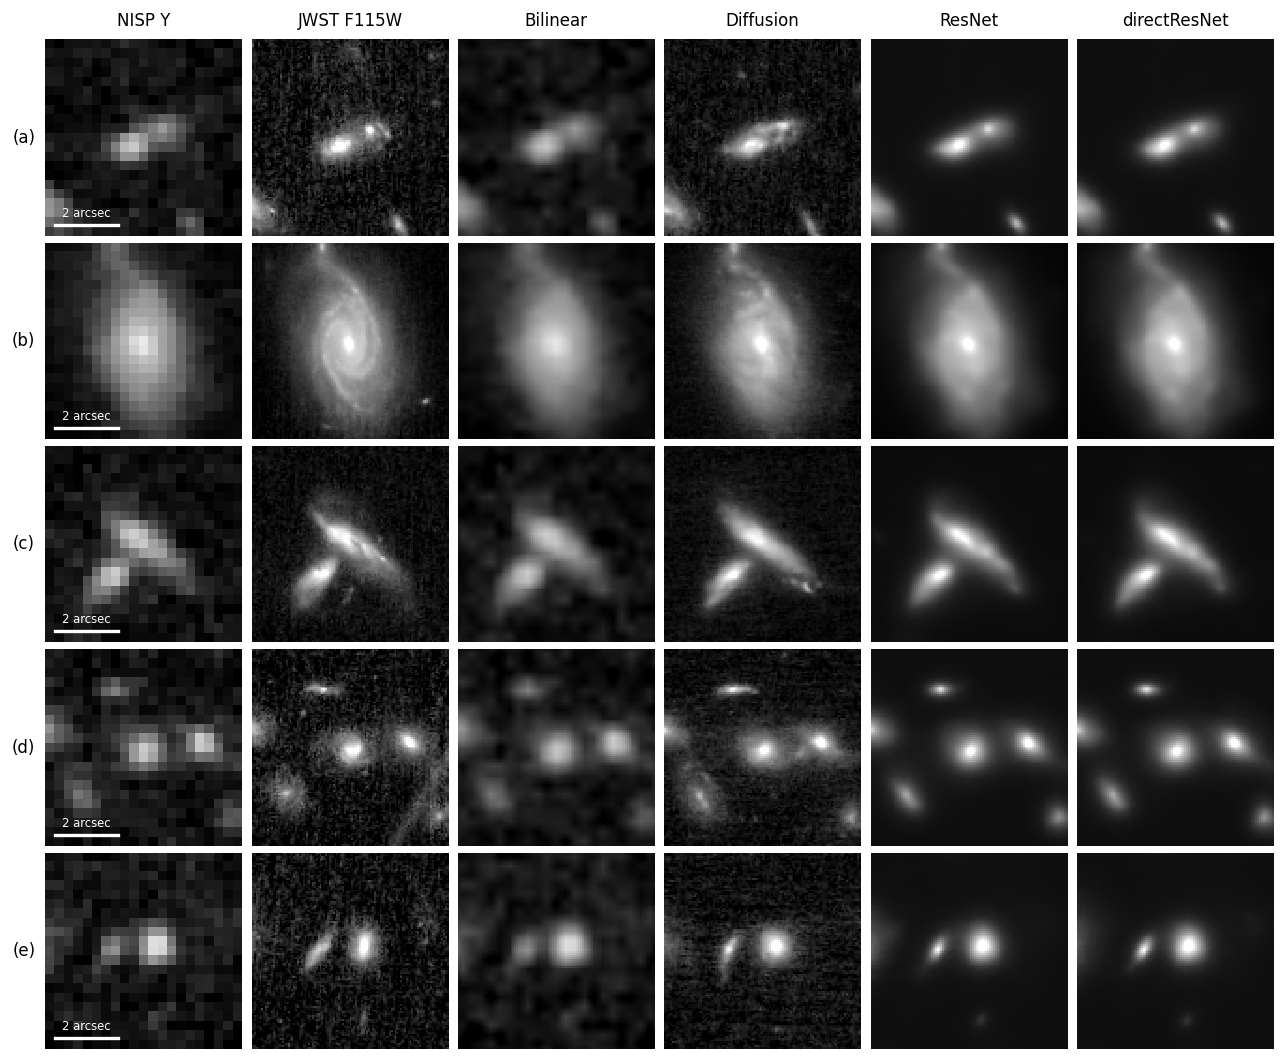

Exported: fig05_galaxy_examples_v05.pdf, fig05_galaxy_examples_v05.svg, fig05_galaxy_examples_v05.png


In [3]:
if ready:
    count = min(N_EXAMPLES, len(ids))
    names = ['nisp', 'jwst', 'bilinear', *PREDICTIONS]
    labels = {'nisp':'NISP Y', 'bilinear':'Bilinear', 'jwst':'JWST F115W', 'legacy':'ResNet',
              'direct5':'directResNet', 'diffusion':'Diffusion', 'diffusion_mean3':'Diffusion mean (3)'}
    fig, axes = plt.subplots(count, len(names), figsize=(10.8, 1.8*count), squeeze=False)
    cmap = plt.get_cmap('gray').copy(); cmap.set_bad('#888888')
    native_edge = (41-CROP_NATIVE)//2
    native_slice = slice(native_edge, native_edge+CROP_NATIVE)
    target_slice = slice(5*native_edge, 5*(native_edge+CROP_NATIVE))
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]
        scale = metadata['nisp_pixel_scale_arcsec'][i]
        half_width = CROP_NATIVE*scale/2
        extent = [-half_width, half_width, -half_width, half_width]
        for j, name in enumerate(names):
            mask = images[name+'_valid'][i].astype(bool) if name in ('nisp','bilinear') else images['jwst_valid'][i].astype(bool)
            crop = native_slice if name == 'nisp' else target_slice
            values = np.ma.array(images[name][i][crop,crop], mask=~mask[crop,crop])
            axes[i,j].imshow(np.arcsinh(values/limit['stretch']), origin='lower', extent=extent,
                interpolation='nearest', cmap=cmap, vmin=np.arcsinh(limit['low']/limit['stretch']),
                vmax=np.arcsinh(limit['high']/limit['stretch']))
            axes[i,j].set_xticks([]); axes[i,j].set_yticks([])
            for spine in axes[i,j].spines.values(): spine.set_visible(False)
            if i == 0: axes[i,j].set_title(labels[name], fontsize=10, pad=8)
        axes[i,0].set_ylabel(f'({chr(97+i)})', rotation=0, labelpad=13, va='center', fontsize=10)
        left, bottom = -half_width+.3, -half_width+.35
        axes[i,0].plot([left,left+2],[bottom,bottom],color='white',lw=2)
        axes[i,0].text(left+1,bottom+.16,'2 arcsec',color='white',ha='center',va='bottom',fontsize=7)
    fig.subplots_adjust(left=.045,right=.995,bottom=.015,top=.95,wspace=.035,hspace=.035)
    plt.show()
    paths = export(fig, f'fig05_galaxy_examples_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path, ROOT/metadata['selection_file']],
        dict(object_ids=ids[:count].tolist(), predictions=PREDICTIONS, crop_native=CROP_NATIVE,
             intensity_limits=metadata['limits_mjy_sr'], checkpoints=metadata['checkpoints'],
             scale='fixed shared per-object asinh intensity; native NISP pixels, no display smoothing'),
        status='Provisional best-checkpoint validation examples; diffusion best available at export')


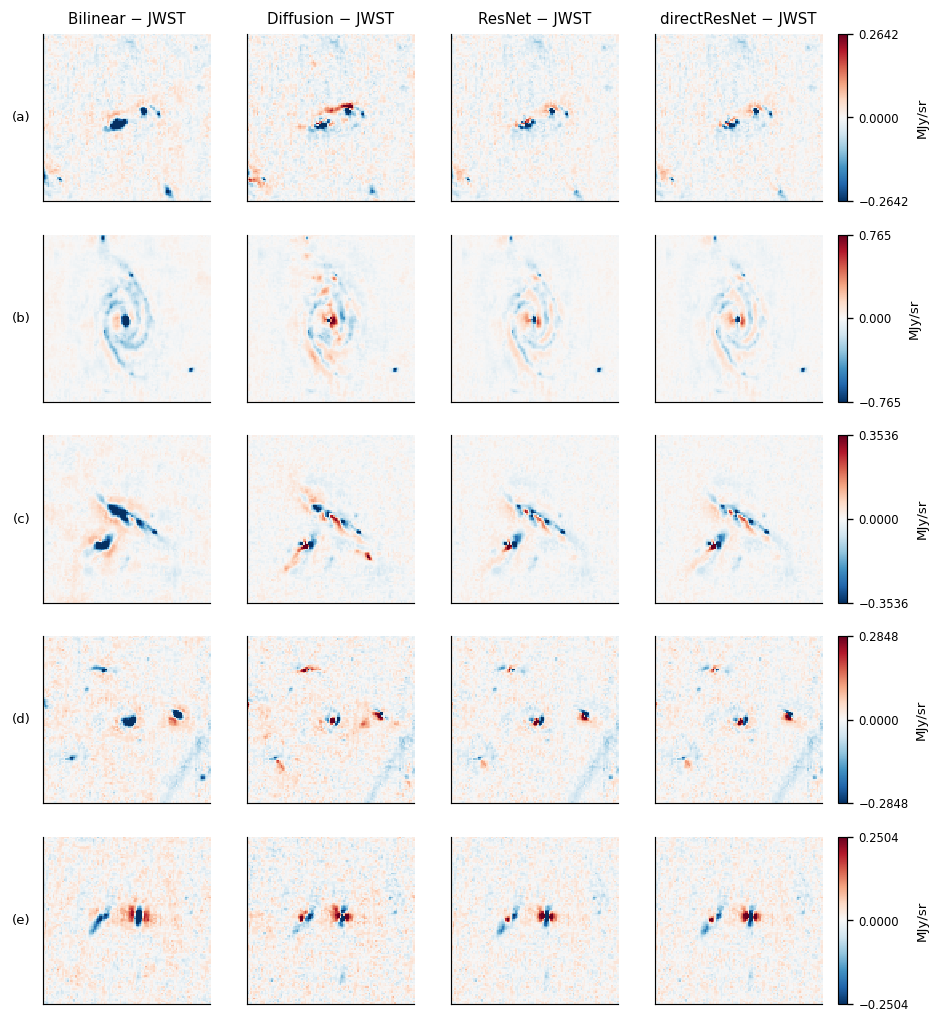

Exported: fig05_galaxy_residuals_v05.pdf, fig05_galaxy_residuals_v05.svg, fig05_galaxy_residuals_v05.png


In [4]:
# Companion residual sheet for reviewing errors; no extra model inference.
if ready:
    residual_names = ['bilinear', *PREDICTIONS]
    residual_fig, residual_axes = plt.subplots(count, len(residual_names),
        figsize=(8.8, 2.1*count), squeeze=False)
    cmap = plt.get_cmap('RdBu_r').copy(); cmap.set_bad('#888888')
    for i in range(count):
        limit = metadata['limits_mjy_sr'][i]['residual']
        mask = images['jwst_valid'][i][target_slice,target_slice].astype(bool)
        for j,name in enumerate(residual_names):
            delta = (images[name][i]-images['jwst'][i])[target_slice,target_slice]
            support = mask & images['bilinear_valid'][i][target_slice,target_slice] if name=='bilinear' else mask
            arr = np.ma.array(delta,mask=~support)
            ax=residual_axes[i,j]
            shown=ax.imshow(arr,origin='lower',interpolation='nearest',cmap=cmap,vmin=-limit,vmax=limit)
            ax.set_xticks([]); ax.set_yticks([])
            if i==0: ax.set_title(labels[name]+' − JWST',fontsize=9)
            if j==0: ax.set_ylabel(f'({chr(97+i)})',rotation=0,labelpad=13,va='center')
        residual_fig.colorbar(shown,ax=list(residual_axes[i]),fraction=.025,pad=.02,
                             label='MJy/sr',ticks=[-limit,0,limit])
    plt.show()
    residual_paths = export(residual_fig, f'fig05_galaxy_residuals_{VERSION}', '05_galaxy_examples.ipynb',
        [bundle_path, metadata_path], dict(predictions=residual_names, crop_native=CROP_NATIVE,
        residual_limits=[x['residual'] for x in metadata['limits_mjy_sr']]),
        status='Companion residual review sheet; same objects, checkpoints and crops as Figure 5')


## Working caption

Selected validation fields illustrating a face-on disk, close projected pairs,
overlapping extended sources and a crowded field with multiple neighbors.
Columns show NISP Y, JWST F115W, bilinear interpolation of NISP, diffusion,
ResNet and directResNet reconstructions. The examples were chosen from observed
images before inspecting their model predictions, with the new fields drawn
from a search for multiple separated peaks in JWST. This illustrative selection
is not statistically representative; neighboring sources are not necessarily
physically associated. Each row uses one shared intensity stretch over a roughly
6.3-arcsec field; scale bars indicate 2 arcsec. Diffusion shows one realization
from its best available checkpoint. Bilinear retains the NISP band and
instrumental response. Checkpoint epochs and selection details are recorded in
the metadata. The separate residual sheet shows each method minus JWST using
a common symmetric linear scale per row.
